# II.D (bonus) — Forecasting the mean BTC price over the next 48 hours with Telegram sentiment

**Objective (brief II.D).** Predict the mean BTC price over the next 48 hours from 200 hours of history and a VADER
sentiment score computed on Telegram; compare ARIMA, ARIMAX and LSTM by MAE with rolling validation, and apply the
Diebold–Mariano test. [A1] §7 runs a similar experiment (200-hour sequences, 48-hour horizon, MAE) to show that the
SNN generalises.

**Target.** With $P_t$ the BTC/USDT hourly close,
$$y_t=\frac{1}{48}\sum_{j=1}^{48}P_{t+j},$$
forecast at origin $t$ from $\{P_s,\ \text{sent}_s:\ t-199\le s\le t\}$.

In [1]:
import contextlib
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import grangercausalitytests
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import binance
from pnd_paper.data.telegram import iter_messages
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
settings.seed_everything()
R = Reporter("IID_bonus_btc_forecast")
SZ = settings.SIZES
HIST, H = 200, 48

## 1. Data

* **Price**: Binance BTC/USDT hourly klines, downloaded from the public archive.
* **Sentiment**: VADER (Hutto & Gilbert, 2014) assigns each message a compound score in $[-1,1]$, a normalised sum of
  lexicon valences adjusted for negation, intensifiers, punctuation and capitals. The hourly sentiment is the mean
  compound score of all Telegram posts of the authors' corpus in that hour, $\text{sent}_t=\frac1{n_t}\sum_{m\in t}
  \text{compound}(m)$, and $n_t$ the message count. The corpus ends in January 2022, which bounds the study period.

In [2]:
cache = settings.CACHE / "sentiment_hourly.parquet"
if cache.is_file():
    sent = pd.read_parquet(cache)
else:
    an = SentimentIntensityAnalyzer()
    start = pd.Timestamp("2020-01-01", tz="UTC").to_pydatetime()
    rows = [(d, an.polarity_scores(t[:500])["compound"]) for _, d, t in iter_messages() if d is not None and d >= start]
    s = pd.DataFrame(rows, columns=["date", "compound"])
    s["hour"] = pd.to_datetime(s.date, utc=True).dt.floor("h")
    sent = s.groupby("hour").compound.agg(["mean", "size"]).rename(columns={"mean": "sent", "size": "n_msg"})
    sent.to_parquet(cache)
start, end = pd.Timestamp("2020-02-07", tz="UTC"), sent.index.max().floor("D")
btc = binance.load_klines("BTCUSDT", "1h", start - pd.Timedelta(days=10), end)
df = pd.DataFrame({"price": btc.close.astype(float)}).join(sent, how="left")
df = df.asfreq("h")
df["price"] = df.price.ffill()
df["sent"] = df.sent.fillna(0.0)
df["n_msg"] = df.n_msg.fillna(0)
df["y"] = df.price[::-1].rolling(H).mean()[::-1].shift(-1)        # mean of P_{t+1..t+48}
df = df.loc[start:]
md(f"Hourly observations: {len(df)} from {df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}; messages scored: "
   f"{int(sent.n_msg.sum()):,}; mean hourly sentiment {df.sent.mean():.3f} (sd {df.sent.std():.3f}).")

Hourly observations: 17233 from 2020-02-07 to 2022-01-25; messages scored: 946,500; mean hourly sentiment 0.243 (sd 0.112).

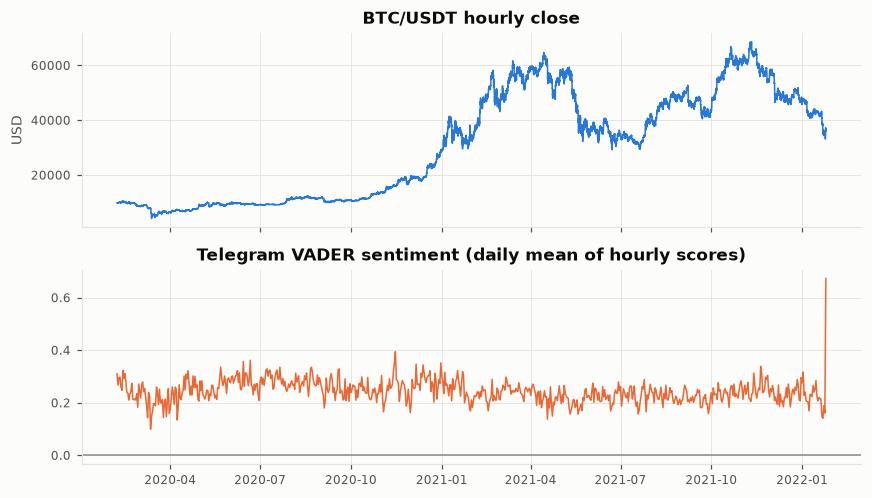

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
axes[0].plot(df.index, df.price, color=SERIES[0], lw=1)
axes[0].set_title("BTC/USDT hourly close")
axes[0].set_ylabel("USD")
daily = df.sent.resample("D").mean()
axes[1].plot(daily.index, daily.values, color=SERIES[1], lw=1)
axes[1].axhline(0, color="#8a8985", lw=1)
axes[1].set_title("Telegram VADER sentiment (daily mean of hourly scores)")
R.fig(fig, "series")
close(fig)

### Does sentiment carry information about future returns? (Granger test)

For hourly log-returns $r_t$, compare the restricted model $r_t=c+\sum_{k=1}^{p}a_kr_{t-k}+u_t$ with the unrestricted
one adding $\sum_{k=1}^{p}b_k\,\text{sent}_{t-k}$. $H_0:b_1=\dots=b_p=0$ (sentiment does not Granger-cause returns) is
tested with $F=\frac{(\mathrm{RSS}_r-\mathrm{RSS}_u)/p}{\mathrm{RSS}_u/(T-2p-1)}\sim F_{p,T-2p-1}$.

In [4]:
gdf = pd.DataFrame({"r": np.log(df.price).diff(), "sent": df.sent}).dropna()
gc_rows = []
for p in (1, 6, 24, 48):
    with contextlib.redirect_stdout(io.StringIO()):     # the function prints every test; keep only the F test
        res = grangercausalitytests(gdf[["r", "sent"]], maxlag=[p])[p][0]["ssr_ftest"]
        rev = grangercausalitytests(gdf[["sent", "r"]], maxlag=[p])[p][0]["ssr_ftest"]
    gc_rows.append({"lags p": p, "F (sent -> r)": res[0], "p (sent -> r)": res[1], "F (r -> sent)": rev[0], "p (r -> sent)": rev[1]})
gc = pd.DataFrame(gc_rows).set_index("lags p")
R.table(gc, "granger")
show(gc, "{:.3g}")
md("\n".join(f"- $p={k}$: sentiment → returns $F={r['F (sent -> r)']:.2f},\\ {S.fmt_p(r['p (sent -> r)'])}$; "
             f"returns → sentiment $F={r['F (r -> sent)']:.2f},\\ {S.fmt_p(r['p (r -> sent)'])}$." for k, r in gc.iterrows()))

,F (sent -> r),p (sent -> r),F (r -> sent),p (r -> sent)
lags p,,,,
1,0.177,0.674,13.7,0.000212
6,1.03,0.405,6.83,2.96e-07
24,0.629,0.917,2.86,3.63e-06
48,0.659,0.967,2.15,7.06e-06


- $p=1$: sentiment → returns $F=0.18,\ p=0.674$; returns → sentiment $F=13.72,\ p=2.12\times10^{-4}$.
- $p=6$: sentiment → returns $F=1.03,\ p=0.405$; returns → sentiment $F=6.83,\ p=2.96\times10^{-7}$.
- $p=24$: sentiment → returns $F=0.63,\ p=0.917$; returns → sentiment $F=2.86,\ p=3.63\times10^{-6}$.
- $p=48$: sentiment → returns $F=0.66,\ p=0.967$; returns → sentiment $F=2.15,\ p=7.06\times10^{-6}$.

## 2. Rolling-origin evaluation design

Origins $t_1<\dots<t_M$ are spaced by 24 hours over the last part of the sample (test period); at each origin,
every model sees only data up to $t_m$. The LSTM is trained once on origins **before** the test period (with the
last 20 % of them as a validation set for early stopping); the ARIMA models are re-estimated at every origin on the
last 200 hours (rolling window).

* **ARIMA$(p,1,q)$** on $\log P$, $p,q\le2$, order chosen by AIC at each origin; the 48 point forecasts
  $\widehat{\log P}_{t+j}$ are mapped back with $\exp$ and averaged.
* **ARIMAX**: the same with the exogenous regressor $\text{sent}_{t-48}$ (lagged by the horizon, so its future
  values are known when forecasting $t+1..t+48$).
* **LSTM**: input the 200-hour window of $[\log P_s-\log P_t,\ \text{sent}_s,\ \log(1+n_s)]$, output
  $\log(y_t/P_t)$, trained with an L1 loss (MAE).
* **Random walk**: $\hat y_t=P_t$, the benchmark any model must beat.

In [5]:
M = SZ.rolling_origins
origins = df.index[df.y.notna()][-1 - 24 * (M - 1)::24][:M]
test_start = origins[0]
md(f"{len(origins)} origins from {origins[0]:%Y-%m-%d %H:%M} to {origins[-1]:%Y-%m-%d %H:%M}, one per day "
   f"({'QUICK' if settings.QUICK else 'FULL'} run).")


def arima_forecast(t, exog=False):
    hist = df.loc[:t].iloc[-HIST:]
    y = np.log(hist.price.values)
    X = hist.sent.shift(H).fillna(0.0).values[:, None] if exog else None
    Xf = df.sent.loc[:t].iloc[-H:].values[:, None] if exog else None
    best = None
    for p in range(3):
        for q in range(3):
            try:
                m = SARIMAX(y, exog=X, order=(p, 1, q), trend="n").fit(disp=False)
            except Exception:
                continue
            if best is None or m.aic < best.aic:
                best = m
    fc = best.forecast(H, exog=Xf)
    return float(np.exp(fc).mean()), best.model.order


rows = []
for t in origins:
    a, oa = arima_forecast(t, False)
    ax_, ox = arima_forecast(t, True)
    rows.append({"origin": t, "y": df.y.loc[t], "P_t": df.price.loc[t], "ARIMA": a, "ARIMAX": ax_, "order ARIMA": str(oa)})
fc = pd.DataFrame(rows).set_index("origin")
fc["random walk"] = fc.P_t

40 origins from 2021-12-15 00:00 to 2022-01-23 00:00, one per day (QUICK run).

In [6]:
def windows(index):
    Xs, ys = [], []
    lp = np.log(df.price.values)
    for t in index:
        i = df.index.get_loc(t)
        if i < HIST:
            continue
        w = slice(i - HIST + 1, i + 1)
        Xs.append(np.c_[lp[w] - lp[i], df.sent.values[w], np.log1p(df.n_msg.values[w])])
        ys.append(np.log(df.y.values[i] / df.price.values[i]))
    return torch.tensor(np.array(Xs), dtype=torch.float32), torch.tensor(np.array(ys), dtype=torch.float32)


class LSTMReg(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.LSTM(3, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        o, _ = self.rnn(x)
        return self.out(o[:, -1]).squeeze(-1)


train_idx = df.index[(df.index < test_start - pd.Timedelta(hours=H)) & df.y.notna()][HIST::6]
cut = int(0.8 * len(train_idx))
Xtr, ytr = windows(train_idx[:cut])
Xva, yva = windows(train_idx[cut:])
Xte, _ = windows(origins)
lstm_preds = []
for sd in [settings.SEED + s for s in range(SZ.seeds)]:
    torch.manual_seed(sd)
    net = LSTMReg()
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    best, state, bad = np.inf, None, 0
    for ep in range(SZ.dl_epochs * 2):
        net.train()
        perm = torch.randperm(len(Xtr))
        for b in range(0, len(perm), 128):
            j = perm[b:b + 128]
            opt.zero_grad()
            loss = (net(Xtr[j]) - ytr[j]).abs().mean()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = (net(Xva) - yva).abs().mean().item()
        if v < best:
            best, state, bad = v, {k: x.clone() for k, x in net.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= 5:
                break
    net.load_state_dict(state)
    with torch.no_grad():
        lstm_preds.append(np.exp(net(Xte).numpy()) * fc.P_t.values)
fc["LSTM"] = np.mean(lstm_preds, axis=0)
R.table(fc, "forecasts")

WindowsPath('C:/Users/Dr.Console/Desktop/Pump-and-Dump-Detection-on-Cryptocurrency-master/results/IID_bonus_btc_forecast/tables/forecasts.csv')

## 3. Results: MAE and Diebold–Mariano tests

$\mathrm{MAE}=\frac1M\sum_m|y_{t_m}-\hat y_{t_m}|$ (USD). For two models with errors $e^{(1)},e^{(2)}$ and loss
differential $d_m=|e^{(1)}_m|-|e^{(2)}_m|$, the Diebold–Mariano statistic is
$$\mathrm{DM}=\frac{\bar d}{\sqrt{\widehat{\mathrm{LRV}}/M}},\qquad
\widehat{\mathrm{LRV}}=\hat\gamma_0+2\sum_{k=1}^{h-1}\Big(1-\frac kh\Big)\hat\gamma_k,$$
with the Harvey–Leybourne–Newbold correction $\mathrm{DM}^*=\mathrm{DM}\sqrt{(M+1-2h+h(h-1)/M)/M}\sim t_{M-1}$.
Forecasts 24 hours apart with a 48-hour target overlap, so $h=2$ autocovariance lags are needed. $H_0$: equal
expected absolute error.

In [7]:
models = ["random walk", "ARIMA", "ARIMAX", "LSTM"]
mae = pd.DataFrame({m: {"MAE (USD)": (fc[m] - fc.y).abs().mean(), "MAPE (%)": 100 * ((fc[m] - fc.y).abs() / fc.y).mean()}
                    for m in models}).T
lstm_seed_mae = [np.abs(p - fc.y.values).mean() for p in lstm_preds]
mae.loc["LSTM", "sd over seeds"] = np.std(lstm_seed_mae, ddof=1) if len(lstm_seed_mae) > 1 else 0.0
R.table(mae, "mae")
show(mae, "{:.2f}")
dm_rows = []
for i, a in enumerate(models):
    for b in models[i + 1:]:
        r = S.diebold_mariano(fc[a] - fc.y, fc[b] - fc.y, h=2)
        dm_rows.append({"model 1": a, "model 2": b, "mean |e1|-|e2|": r["mean_loss_diff"], "DM*": r["DM_HLN"], "p": r["p"]})
dm = pd.DataFrame(dm_rows)
dm["p (Holm)"] = S.holm(dm.p)
R.table(dm, "diebold_mariano", index=False)
show(dm.set_index(["model 1", "model 2"]), "{:.3g}")
md("\n".join(f"- {r['model 1']} vs {r['model 2']}: $\\bar d={r['mean |e1|-|e2|']:.1f}$ USD, $\\mathrm{{DM}}^*={r['DM*']:.2f}$, "
             f"Holm-adjusted ${S.fmt_p(r['p (Holm)'])}$ → {S.decision(r['p (Holm)'])}." for _, r in dm.iterrows()))

,MAE (USD),MAPE (%),sd over seeds
random walk,756.03,1.73,nan
ARIMA,757.83,1.73,nan
ARIMAX,758.43,1.73,nan
LSTM,801.34,1.84,0.38


- random walk vs ARIMA: $\bar d=-1.8$ USD, $\mathrm{DM}^*=-1.38$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- random walk vs ARIMAX: $\bar d=-2.4$ USD, $\mathrm{DM}^*=-0.80$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- random walk vs LSTM: $\bar d=-45.3$ USD, $\mathrm{DM}^*=-1.35$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- ARIMA vs ARIMAX: $\bar d=-0.6$ USD, $\mathrm{DM}^*=-0.26$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- ARIMA vs LSTM: $\bar d=-43.5$ USD, $\mathrm{DM}^*=-1.29$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.
- ARIMAX vs LSTM: $\bar d=-42.9$ USD, $\mathrm{DM}^*=-1.28$, Holm-adjusted $p=1.000$ → do not reject $H_0$ at $\alpha=0.05$.

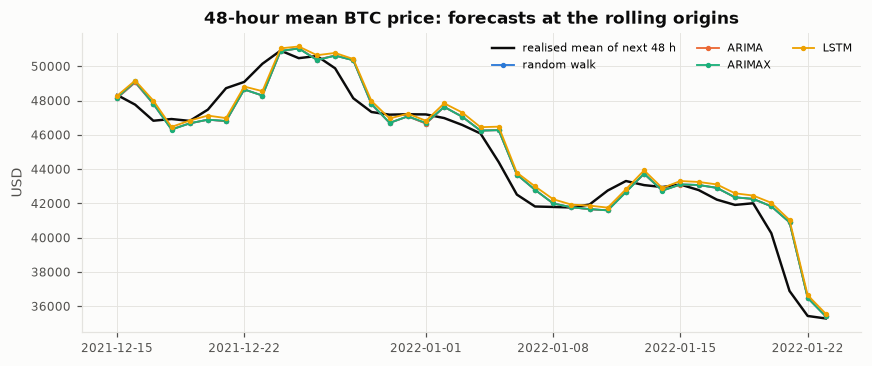

[A1] Table 8 reports an MAE of 756.90 USD at 48 h for its SNN on a different period (test after 2021-12-19, up to May 2022) and with a different target definition, so the levels are not comparable; the comparison that matters is with the random walk on the same origins.

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(fc.index, fc.y, color="#0b0b0b", lw=1.6, label="realised mean of next 48 h")
for i, m in enumerate(models):
    ax.plot(fc.index, fc[m], color=SERIES[i], lw=1.2, marker=".", label=m)
ax.set_title("48-hour mean BTC price: forecasts at the rolling origins")
ax.set_ylabel("USD")
ax.legend(fontsize=7, ncol=3)
R.fig(fig, "forecasts")
close(fig)
md("[A1] Table 8 reports an MAE of 756.90 USD at 48 h for its SNN on a different period (test after 2021-12-19, up "
   "to May 2022) and with a different target definition, so the levels are not comparable; the comparison that "
   "matters is with the random walk on the same origins.")

## 4. Interpretation (QUICK run: 40 daily origins, 2 LSTM seeds)

* **Sentiment follows prices, not the reverse.** The Granger tests do not reject "sentiment does not cause
  returns" at any lag ($p\ge0.40$), but strongly reject "returns do not cause sentiment" ($p<10^{-3}$ at every
  lag). Telegram crypto channels react to price moves (celebrating rallies, lamenting drops) rather than anticipate
  them. A predictor built on this sentiment can at best echo information already in the price.
* **No model beats the random walk.** Over the 40 origins (mid-December 2021 to January 2022) the random walk
  $\hat y_t=P_t$ has an MAE of about 756 USD (1.7 %). ARIMA and ARIMAX are within 2–3 USD of it, and the LSTM is about
  45 USD worse. None of the Diebold–Mariano tests rejects equal accuracy, even before the Holm correction
  ($p\ge0.18$). Adding sentiment to ARIMA changes the MAE by less than a dollar, consistent with the Granger result.
  This is the expected outcome for a liquid asset at a 48-hour horizon: its price is close to a martingale.
* **Comparison with [A1] §7.** The paper reports an MAE of 756.90 USD at 48 h for its SNN (test period after
  2021-12-19). Our random walk reaches almost the same value (756 USD) on an overlapping period. Unless the paper's
  number beats a random walk on its own sample, which the paper does not report, the experiment shows the
  difficulty of the task rather than the model's skill.

**Limitations.** The corpus ends in January 2022, which limits the test period to 40 overlapping 48-hour windows;
the DM test therefore has little power, and the full run (200 origins on a longer period) is needed for firmer
conclusions. VADER's lexicon is not tuned for crypto slang ("moon", "rekt", rocket emojis), which attenuates the
signal.